# 02 · LVEF: predizione e ruolo del QRS

**Contesto.** I colleghi hanno osservato pazienti con feature simili ma `lvef_value` diverso, e i medici hanno ipotizzato che la differenza possa dipendere da `qrs_duration` (un QRS largo, ad esempio per blocco di branca sinistra, cambia la forma dell'ECG e la sua relazione con la funzione ventricolare). In statistica il QRS sarebbe un *modificatore d'effetto*.

Il notebook:
1. predice `lvef_value` (regressione) e `lvef_lte_45_flag` (classificazione) con più modelli;
2. testa l'ipotesi del QRS in **tre modi indipendenti**: stratificazione, importanza della feature, coppie di pazienti simili con LVEF diversa.

Il "a parità di ..." che non ricordavi è un parametro: `MATCH_ON` nella sezione 4. Chiedi ai colleghi quale insieme usavano e sostituiscilo.

In [1]:
#@title Setup comune: configurazione, caricamento dati, funzioni di utilità
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ===================== CONFIGURAZIONE =====================
DATA_DIR = Path(os.environ.get("ECHONEXT_DIR", "/home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1"))   # cartella con lo zip (o i file già estratti)
OUT_DIR  = Path(os.environ.get("ECHONEXT_OUT", str(Path.home() / "echonext_results")))  # dove salvare i risultati
SEED = 42
DEBUG_N = int(os.environ.get("ECHONEXT_DEBUG_N", "0")) or None  # es. 3000 = prova rapida con 3000 righe per split
RUN_FINAL_TEST = False   # lasciare False finché pipeline e scelte non sono congelate (vedi ultima cella)
TARGET = "shd_moderate_or_greater_flag"
# ==========================================================

def locate_dataset(root):
    """Trova il CSV dei metadati (anche in sottocartelle, anche .csv.gz); se c'è solo uno zip lo estrae in <root>/extracted.
    Se non trova nulla, stampa il contenuto della cartella per capire cosa manca."""
    import zipfile
    root = Path(root).expanduser()
    if not root.exists(): raise FileNotFoundError(f"Cartella non trovata: {root}")
    def find_csv(base):
        c = [p for p in base.rglob("*") if p.is_file() and "metadata" in p.name.lower() and p.name.lower().endswith((".csv", ".csv.gz"))]
        return sorted(c, key=lambda p: ("100k" not in p.name.lower(), len(str(p))))
    hits = find_csv(root)
    if hits: return hits[0]
    target = root / "extracted"
    for z in sorted(root.rglob("*.zip")):
        with zipfile.ZipFile(z) as zf:
            if any("metadata" in n.lower() and ".csv" in n.lower() for n in zf.namelist()):
                print(f"estraggo {z.name} in {target} ... (può richiedere minuti)"); zf.extractall(target); break
    hits = find_csv(target) if target.exists() else []
    if hits: return hits[0]
    files = sorted(p for p in root.rglob("*") if p.is_file())
    listing = "\n".join(f"  {p.relative_to(root)}  ({p.stat().st_size / 1e6:.2f} MB)" for p in files[:30])
    raise FileNotFoundError(f"Nessun CSV di metadata in {root}.\nContenuto trovato ({len(files)} file):\n{listing or '  (nessun file)'}\n"
                            "Se vedi solo index.html o file di pochi KB il download non è andato a buon fine (credenziali o DUA non firmato); "
                            "se i file stanno altrove, punta DATA_DIR alla cartella giusta.")

META_PATH = locate_dataset(DATA_DIR)
DATA_DIR = META_PATH.parent
print("dati in:", DATA_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

# Feature ECG ammesse come INPUT dei modelli (misure automatiche dell'ECG + demografia)
ECG_FEATURES = ["sex", "ventricular_rate", "atrial_rate", "pr_interval", "qrs_duration", "qt_corrected", "age_at_ecg"]
# Etichette binarie derivate dall'ecocardiogramma (possibili TARGET)
FLAG_COLS = ["shd_moderate_or_greater_flag", "lvef_lte_45_flag", "lvwt_gte_13_flag",
             "aortic_stenosis_moderate_or_greater_flag", "aortic_regurgitation_moderate_or_greater_flag",
             "mitral_regurgitation_moderate_or_greater_flag", "tricuspid_regurgitation_moderate_or_greater_flag",
             "pulmonary_regurgitation_moderate_or_greater_flag", "rv_systolic_dysfunction_moderate_or_greater_flag",
             "pericardial_effusion_moderate_large_flag", "pasp_gte_45_flag", "tr_max_gte_32_flag"]
# Colonne derivate dall'eco: MAI usarle come input (leakage del target)
ECHO_ONLY_COLS = ["aortic_stenosis_value", "aortic_regurgitation_value", "mitral_regurgitation_value",
                  "tricuspid_regurgitation_value", "pulmonary_regurgitation_value", "rv_systolic_function_value",
                  "pericardial_effusion_value", "ivs_measurement", "lvpw_measurement", "pasp_value",
                  "tr_max_velocity_value", "lvef_value"] + FLAG_COLS
assert not set(ECG_FEATURES) & set(ECHO_ONLY_COLS), "leakage: feature eco tra gli input"

# ---------- caricamento metadata ----------
meta = pd.read_csv(META_PATH)
meta["sex"] = meta["sex"].astype(str).str.lower().map({"male": 1, "female": 0, "m": 1, "f": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
assert meta["sex"].notna().mean() > 0.9, "colonna sex non interpretata: controlla i valori"
# l'ordine delle righe del CSV corrisponde all'ordine dei file .npy di ciascuno split
meta["row_in_split"] = meta.groupby("split").cumcount()
if DEBUG_N:
    meta = meta.groupby("split").head(DEBUG_N)
train, val, test = (meta[meta.split == s].copy() for s in ("train", "val", "test"))
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  (no_split={int((meta.split=='no_split').sum()):,})")

# ---------- metriche ----------
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error, r2_score

def safe_auc(y, p):
    y = np.asarray(y)
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def boot_ci(y, p, fn=safe_auc, n=300, seed=0):
    """Intervallo di confidenza al 95% per bootstrap sulle righe (val/test hanno 1 ECG per paziente)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); v = fn(y[i], p[i])
        if not np.isnan(v): vals.append(v)
    return (np.percentile(vals, 2.5), np.percentile(vals, 97.5)) if vals else (np.nan, np.nan)

def fmt_auc(y, p):
    lo, hi = boot_ci(y, p)
    return safe_auc(y, p), lo, hi

# ---------- dati e modelli ----------
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

def get_xy(df, target, features=ECG_FEATURES):
    """Restituisce X, y, df filtrato (righe con target mancante escluse)."""
    d = df.dropna(subset=[target])
    y = d[target].values
    y = y.astype(int) if target in FLAG_COLS else y.astype(float)
    return d[list(features)].astype(float), y, d

def model_zoo(seed=SEED):
    """Più modelli da confrontare: lineare, lineare sparso (Lasso), foresta, boosting, rete densa (MLP)."""
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True)  # l'indicatore cattura "PR/atrial rate mancante" (es. fibrillazione)
    return {
        "logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
        "lasso_logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
        "random_forest": make_pipeline(imp(), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=seed)),
        "hist_gb": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=seed),
        "mlp_dense": make_pipeline(imp(), StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=200, random_state=seed)),
    }

def eval_models(Xtr, ytr, Xva, yva, models=None):
    """Addestra su train, valuta su val. Ritorna tabella AUROC (con IC95%) e predizioni."""
    rows, preds = [], {}
    for name, m in (models or model_zoo()).items():
        t0 = time.time(); m.fit(Xtr, ytr); p = m.predict_proba(Xva)[:, 1]
        a, lo, hi = fmt_auc(yva, p)
        rows.append(dict(model=name, AUROC=a, CI_lo=lo, CI_hi=hi, AUPRC=average_precision_score(yva, p),
                         prev_val=float(np.mean(yva)), n_val=len(yva), sec=round(time.time() - t0, 1)))
        preds[name] = p
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True), preds

def oof_proba(model, X, y, groups, n_splits=5):
    """Predizioni out-of-fold con CV raggruppata per paziente (nessun paziente in train e test dello stesso fold)."""
    return cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits), method="predict_proba")[:, 1]

def add_groups(df):
    """Aggiunge fasce di QRS ed età, usate per stratificare."""
    d = df.copy()
    d["qrs_bin"] = pd.cut(d.qrs_duration, [0, 100, 120, 10000], labels=["<100", "100-119", ">=120"], right=False).astype(object)
    d["age_bin"] = pd.cut(d.age_at_ecg, [0, 50, 65, 75, 200], labels=["<50", "50-64", "65-74", ">=75"], right=False).astype(object)
    return d

dati in: /home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1
train=72,475  val=4,626  test=5,442  (no_split=17,457)


## 1 · Dati e distribuzione di LVEF

`lvef_value` è disponibile solo per gli ECG con eco entro un anno; le altre righe vengono escluse.

righe con LVEF: train=66,018  val=4,112


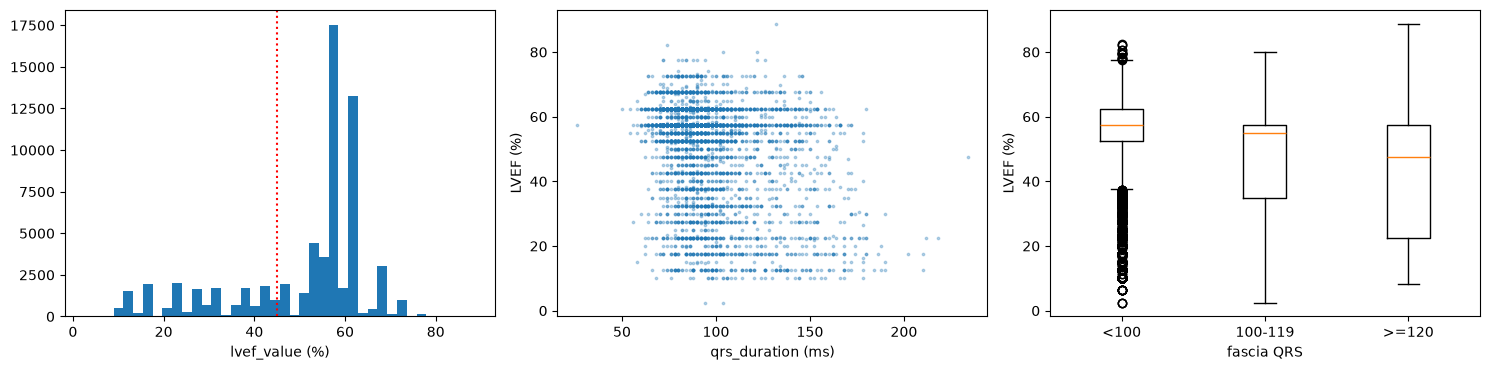

Spearman(QRS, LVEF) = -0.24


In [2]:
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.neural_network import MLPRegressor

tr = add_groups(train.dropna(subset=["lvef_value"])); va = add_groups(val.dropna(subset=["lvef_value"]))
print(f"righe con LVEF: train={len(tr):,}  val={len(va):,}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(tr.lvef_value, bins=40); ax[0].set_xlabel("lvef_value (%)"); ax[0].axvline(45, color="r", ls=":")
ax[1].scatter(tr.qrs_duration.sample(min(5000, len(tr)), random_state=0), tr.lvef_value.loc[tr.qrs_duration.sample(min(5000, len(tr)), random_state=0).index], s=3, alpha=.3)
ax[1].set_xlabel("qrs_duration (ms)"); ax[1].set_ylabel("LVEF (%)")
order = ["<100", "100-119", ">=120"]
ax[2].boxplot([tr.loc[tr.qrs_bin == g, "lvef_value"].dropna() for g in order]); ax[2].set_xticklabels(order); ax[2].set_xlabel("fascia QRS"); ax[2].set_ylabel("LVEF (%)")
plt.tight_layout(); plt.show()
print("Spearman(QRS, LVEF) =", round(stats.spearmanr(tr.qrs_duration, tr.lvef_value, nan_policy="omit")[0], 3))

## 2 · Regressione di LVEF con più modelli

Metriche su validation: MAE (punti percentuali), R², correlazione di Spearman. Il riferimento "predici sempre la media del train" dà il MAE da battere.

In [3]:
imp = lambda: SimpleImputer(strategy="median", add_indicator=True)
def reg_zoo():
    return {
        "ridge": make_pipeline(imp(), StandardScaler(), Ridge(alpha=1.0)),
        "random_forest": make_pipeline(imp(), RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
        "hist_gb": HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=250, random_state=SEED),
        "mlp_dense": make_pipeline(imp(), StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=200, random_state=SEED)),
    }
Xtr, ytr = tr[ECG_FEATURES].astype(float), tr.lvef_value.values; Xva, yva = va[ECG_FEATURES].astype(float), va.lvef_value.values
rows = [dict(model="baseline (media del train)", MAE=mean_absolute_error(yva, np.full_like(yva, ytr.mean())), R2=0.0, Spearman=np.nan)]
reg_preds = {}
for name, m in reg_zoo().items():
    m.fit(Xtr, ytr); p = m.predict(Xva); reg_preds[name] = p
    rows.append(dict(model=name, MAE=mean_absolute_error(yva, p), R2=r2_score(yva, p), Spearman=stats.spearmanr(yva, p)[0]))
reg_res = pd.DataFrame(rows); display(reg_res.round(3)); reg_res.to_csv(OUT_DIR / "02_lvef_regressione.csv", index=False)

# Classificazione LVEF <= 45%
Xc_tr, yc_tr, _ = get_xy(train, "lvef_lte_45_flag"); Xc_va, yc_va, _ = get_xy(val, "lvef_lte_45_flag")
cls_res, _ = eval_models(Xc_tr, yc_tr, Xc_va, yc_va); print("\nClassificazione lvef_lte_45_flag:"); display(cls_res.round(3))
cls_res.to_csv(OUT_DIR / "02_lvef_lte45_classificazione.csv", index=False)

,model,MAE,R2,Spearman
0,baseline (media del train),11.192,0.000,NaN
1,ridge,9.727,0.146,0.332
2,random_forest,9.544,0.152,0.325
3,hist_gb,9.538,0.163,0.341
4,mlp_dense,9.574,0.158,0.337



Classificazione lvef_lte_45_flag:


,model,AUROC,CI_lo,CI_hi,AUPRC,prev_val,n_val,sec
0,hist_gb,0.764,0.748,0.782,0.443,0.187,4626,0.8
1,random_forest,0.762,0.745,0.778,0.443,0.187,4626,2.6
2,lasso_logreg,0.759,0.742,0.774,0.425,0.187,4626,0.5
3,logreg,0.758,0.742,0.774,0.425,0.187,4626,0.5
4,mlp_dense,0.756,0.738,0.773,0.440,0.187,4626,3.4


## 3 · Il QRS cambia la relazione? Due test diretti

**(a) Stratificazione.** Un modello dedicato a ogni fascia di QRS fa meglio del modello globale sulla stessa fascia?
**(b) Importanza.** Quanto R² si perde togliendo ciascuna feature (con riaddestramento)? Se il QRS pesa molto, è importante, ma non dice ancora se *modifica* le relazioni delle altre.

In [4]:
best = "hist_gb"
glob = reg_zoo()[best].fit(Xtr, ytr); pg = glob.predict(Xva)
rows = []
for g in order:
    mt, mv = (tr.qrs_bin == g).values, (va.qrs_bin == g).values
    if mv.sum() < 50 or mt.sum() < 200: continue
    loc = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED).fit(Xtr[mt], ytr[mt])
    pl = loc.predict(Xva[mv])
    rows.append(dict(fascia_QRS=g, n_val=int(mv.sum()), LVEF_media_val=yva[mv].mean(), MAE_globale=mean_absolute_error(yva[mv], pg[mv]),
                     MAE_locale=mean_absolute_error(yva[mv], pl), R2_globale=r2_score(yva[mv], pg[mv]), R2_locale=r2_score(yva[mv], pl)))
display(pd.DataFrame(rows).round(3))

# (b) importanza per riaddestramento senza la feature
base_r2 = r2_score(yva, pg); imp_rows = []
for f in ECG_FEATURES:
    cols = [c for c in ECG_FEATURES if c != f]
    m = reg_zoo()[best].fit(Xtr[cols], ytr); imp_rows.append((f, base_r2 - r2_score(yva, m.predict(Xva[cols]))))
display(pd.DataFrame(imp_rows, columns=["feature_rimossa", "perdita_di_R2"]).sort_values("perdita_di_R2", ascending=False).round(4))

# LVEF media per età x fascia QRS (se le curve hanno pendenze diverse, c'è interazione)
tab = tr.groupby(["age_bin", "qrs_bin"]).lvef_value.agg(["mean", "size"]).unstack("qrs_bin")
display(tab["mean"][order].reindex(["<50", "50-64", "65-74", ">=75"]).round(1))

,fascia_QRS,n_val,LVEF_media_val,MAE_globale,MAE_locale,R2_globale,R2_locale
0,<100,2953,55.537,8.176,8.164,0.048,0.055
1,100-119,612,49.053,12.327,12.248,0.103,0.107
2,>=120,547,44.620,13.771,13.641,0.147,0.156


,feature_rimossa,perdita_di_R2
4,qrs_duration,0.0475
5,qt_corrected,0.0205
0,sex,0.0066
1,ventricular_rate,0.0034
3,pr_interval,0.0032
2,atrial_rate,0.0002
6,age_at_ecg,-0.0020


qrs_bin,<100,100-119,>=120
age_bin,,,
<50,53.4,48.7,40.9
50-64,53.3,47.6,43.6
65-74,53.7,46.5,41.5
>=75,53.7,47.5,43.3


## 4 · Coppie di pazienti simili con LVEF diverso

Replica l'osservazione dei colleghi. Per ogni ECG si cerca il paziente **diverso** più simile secondo le feature in `MATCH_ON` (il QRS è escluso per costruzione), poi si guarda:
- se `|ΔLVEF|` cresce con `|ΔQRS|` (correlazione di Spearman);
- tra le coppie con LVEF molto diverso (≥ 15 punti) rispetto a quelle con LVEF simile (< 5), se il QRS differisce di più;
- se, nelle coppie con LVEF diverso, il membro con LVEF più basso ha il QRS più largo (test dei segni di Wilcoxon).

**Da fare:** sostituire `MATCH_ON` con le feature usate dai colleghi quando le ricordi.

coppie usate: 13,200 | LVEF molto diverso (>= 15): 4,921 | simile (< 5): 3,195
Spearman(|ΔLVEF|, |ΔQRS|) = 0.098  (p=1.3e-29)
|ΔQRS| mediano: coppie LVEF diverso=14.0 ms vs simile=12.0 ms  (Mann-Whitney p=6.2e-20)
Nelle coppie con LVEF diverso, QRS del membro a LVEF più bassa - altro: mediana=4.0 ms (Wilcoxon p=8.1e-52)


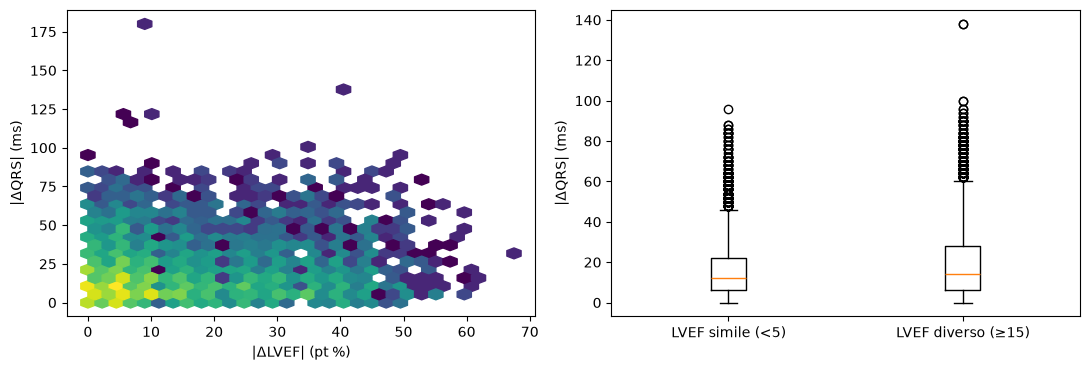

In [5]:
from sklearn.neighbors import NearestNeighbors
MATCH_ON = ["age_at_ecg", "sex", "ventricular_rate", "pr_interval", "qt_corrected"]   # <-- modifica qui ("a parità di ...")
MAX_PAIR_DIST_QUANTILE = 0.20   # si tengono solo il 20% di coppie più simili
D_BIG, D_SMALL = 15, 5          # soglie |ΔLVEF| (punti percentuali)

pool = tr.reset_index(drop=True)
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(pool[MATCH_ON].astype(float)))
K = 8
dist, idx = NearestNeighbors(n_neighbors=K + 1).fit(Z).kneighbors(Z)
pk = pool.patient_key.values
pairs = []
for i in range(len(pool)):
    for d_, j in zip(dist[i, 1:], idx[i, 1:]):
        if pk[j] != pk[i]:           # il vicino deve essere un paziente diverso
            pairs.append((i, j, d_)); break
P = pd.DataFrame(pairs, columns=["i", "j", "dist"])
P = P[P.dist <= P.dist.quantile(MAX_PAIR_DIST_QUANTILE)].copy()
P["dLVEF"] = np.abs(pool.lvef_value.values[P.i] - pool.lvef_value.values[P.j])
P["dQRS"] = np.abs(pool.qrs_duration.values[P.i] - pool.qrs_duration.values[P.j])
low_is_i = pool.lvef_value.values[P.i] < pool.lvef_value.values[P.j]
qrs_low = np.where(low_is_i, pool.qrs_duration.values[P.i], pool.qrs_duration.values[P.j])
qrs_high = np.where(low_is_i, pool.qrs_duration.values[P.j], pool.qrs_duration.values[P.i])
P["dQRS_signed"] = qrs_low - qrs_high    # QRS del membro con LVEF più basso meno QRS dell'altro
P = P.dropna(subset=["dQRS"])
big, small = P[P.dLVEF >= D_BIG], P[P.dLVEF < D_SMALL]
print(f"coppie usate: {len(P):,} | LVEF molto diverso (>= {D_BIG}): {len(big):,} | simile (< {D_SMALL}): {len(small):,}")
rho, p_rho = stats.spearmanr(P.dLVEF, P.dQRS); print(f"Spearman(|ΔLVEF|, |ΔQRS|) = {rho:.3f}  (p={p_rho:.2g})")
if len(big) > 20 and len(small) > 20:
    u = stats.mannwhitneyu(big.dQRS, small.dQRS, alternative="greater")
    print(f"|ΔQRS| mediano: coppie LVEF diverso={big.dQRS.median():.1f} ms vs simile={small.dQRS.median():.1f} ms  (Mann-Whitney p={u.pvalue:.2g})")
    w = stats.wilcoxon(big.dQRS_signed.dropna(), alternative="greater")
    print(f"Nelle coppie con LVEF diverso, QRS del membro a LVEF più bassa - altro: mediana={big.dQRS_signed.median():.1f} ms (Wilcoxon p={w.pvalue:.2g})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hexbin(P.dLVEF, P.dQRS, gridsize=30, bins="log", cmap="viridis"); ax[0].set_xlabel("|ΔLVEF| (pt %)"); ax[0].set_ylabel("|ΔQRS| (ms)")
ax[1].boxplot([small.dQRS, big.dQRS]); ax[1].set_xticklabels([f"LVEF simile (<{D_SMALL})", f"LVEF diverso (≥{D_BIG})"]); ax[1].set_ylabel("|ΔQRS| (ms)")
plt.tight_layout(); plt.show()

**Come leggere.** Se `|ΔQRS|` è chiaramente più grande nelle coppie con LVEF diverso e il QRS del membro con LVEF più basso è più largo, l'ipotesi dei medici è supportata dai dati: il QRS è una variabile da usare per **stratificare** (vedi notebook 03) oppure da dare ai modelli con interazioni. Se non emerge nulla, anche quello è un risultato utile da riportare.

Cautela: coppie simili sulle sole 5 misure tabulari restano pazienti molto diversi clinicamente (terapie, comorbidità), quindi un'associazione osservata non è una prova causale.

## 5 · Valutazione finale su test (una sola volta)

In [7]:
if RUN_FINAL_TEST:
    te = add_groups(test.dropna(subset=["lvef_value"])); Xte, yte = te[ECG_FEATURES].astype(float), te.lvef_value.values
    pt = glob.predict(Xte)
    print(f"TEST ({best}) MAE={mean_absolute_error(yte, pt):.2f}  R2={r2_score(yte, pt):.3f}  Spearman={stats.spearmanr(yte, pt)[0]:.3f}")
    for g in order:
        m = (te.qrs_bin == g).values
        if m.sum() > 30: print(f"  QRS {g}: n={int(m.sum())}  MAE={mean_absolute_error(yte[m], pt[m]):.2f}  R2={r2_score(yte[m], pt[m]):.3f}")
else:
    print("RUN_FINAL_TEST=False: test non toccato.")

TEST (hist_gb) MAE=9.21  R2=0.180  Spearman=0.351
  QRS <100: n=3497  MAE=7.80  R2=0.039
  QRS 100-119: n=697  MAE=11.43  R2=0.140
  QRS >=120: n=633  MAE=14.51  R2=0.132
